In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
from tqdm import tqdm
from cartopy import feature as cf
from cartopy import crs as ccrs
from cmocean import plots, cm
import os
from pathlib import Path

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT    / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [3]:
world_map = gpd.read_file(DATA / 'simplified-world-map' / 'world-map.shp')
world_map = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

In [4]:
country_raster_50km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-50km.tif')
country_raster_50km = country_raster_50km_.read(1)

In [5]:
def draw_RWR_maps(taxon='mammals', res='50km'):
    country_raster_ = rio.open(f"../results/country-rasters/country-raster-eck4-{res}.tif")
    display_extent = [country_raster_.bounds.left, country_raster_.bounds.right, country_raster_.bounds.bottom, country_raster_.bounds.top]
    country_raster = country_raster_.read(1)

    RWR = rio.open(f'../results/area-of-habitat-{res}/rarity-weighted-richness-{taxon}-{res}.tif').read(1)
    RWR_CR = rio.open(f'../results/area-of-habitat-{res}/rarity-weighted-richness-{taxon}-CR-{res}.tif').read(1)
    RWR_EN = rio.open(f'../results/area-of-habitat-{res}/rarity-weighted-richness-{taxon}-EN-{res}.tif').read(1)
    RWR_VU = rio.open(f'../results/area-of-habitat-{res}/rarity-weighted-richness-{taxon}-VU-{res}.tif').read(1)
    RWR_NT = rio.open(f'../results/area-of-habitat-{res}/rarity-weighted-richness-{taxon}-NT-{res}.tif').read(1)

    RWR_plot = np.where((RWR > 0) & (country_raster > 0), RWR, np.nan)
    RWR_CR_plot = np.where((RWR_CR > 0) & (country_raster > 0), RWR_CR, np.nan)
    RWR_EN_plot = np.where((RWR_EN > 0) & (country_raster > 0), RWR_EN, np.nan)
    RWR_VU_plot = np.where((RWR_VU > 0) & (country_raster > 0), RWR_VU, np.nan)
    RWR_NT_plot = np.where((RWR_NT > 0) & (country_raster > 0), RWR_NT, np.nan)

    vmin, vmax = np.nanmin(RWR_plot), np.nanmax(RWR_plot)
    vmin_CR, vmax_CR = np.nanmin(RWR_CR_plot), np.nanmax(RWR_CR_plot)
    vmin_EN, vmax_EN = np.nanmin(RWR_EN_plot), np.nanmax(RWR_EN_plot)
    vmin_VU, vmax_VU = np.nanmin(RWR_VU_plot), np.nanmax(RWR_VU_plot)
    vmin_NT, vmax_NT = np.nanmin(RWR_NT_plot), np.nanmax(RWR_NT_plot)

    print(np.min([vmin_CR, vmin_EN, vmin_VU, vmin_NT]),  vmax)

    fig = plt.figure(figsize=(9, 10), constrained_layout=True)
    plt.rcParams['font.family'] = 'Arial' 

    ax1 = plt.subplot(311, projection=ccrs.EckertIV())
    world_map_eck4.plot(color='none', edgecolor='grey', lw=0.1, ax=ax1, zorder=13)
    world_map_eck4.plot(color='lightgrey', edgecolor='none', lw=0.1, ax=ax1, zorder=0)
    im1 = ax1.imshow(RWR_plot, norm=LogNorm(vmin=1e-7, vmax=37 if taxon == 'vertebrates' else 2e1), cmap='jet', interpolation='nearest', origin='upper', extent=display_extent, zorder=1)
    ax1.set_ylim(-7.2e6, 8.6e6)
    ax1.set_axis_off()
    ax1.set_title('a', loc='left', fontdict={'size':16, 'weight': 'semibold'})

    cax1 = ax1.inset_axes([0.05, 0.15, 0.03, 0.5]) 
    cbar1 = fig.colorbar(im1, cax=cax1, orientation='vertical', label='RWR')

    ax2 = plt.subplot(323, projection=ccrs.EckertIV())
    world_map_eck4.plot(color='none', edgecolor='grey', lw=0.1, ax=ax2, zorder=13)
    world_map_eck4.plot(color='lightgrey', edgecolor='none', lw=0.1, ax=ax2, zorder=0)
    im2 = ax2.imshow(RWR_CR_plot, norm=LogNorm(vmin=1e-7, vmax=37 if taxon == 'vertebrates' else 2e1), cmap='jet', interpolation='nearest', origin='upper', extent=display_extent, zorder=1)
    ax2.set_ylim(-7.2e6, 8.6e6)
    ax2.set_axis_off()
    ax2.set_title('b', loc='left', fontdict={'size':16, 'weight': 'semibold'})
    cax2 = ax2.inset_axes([0.30, -0.1, 0.5, 0.05]) 
    cbar2 = fig.colorbar(im2, cax=cax2, orientation='horizontal', label='RWR')

    ax3 = plt.subplot(324, projection=ccrs.EckertIV())
    world_map_eck4.plot(color='none', edgecolor='grey', lw=0.1, ax=ax3, zorder=13)
    world_map_eck4.plot(color='lightgrey', edgecolor='none', lw=0.1, ax=ax3, zorder=0)
    im3 = ax3.imshow(RWR_EN_plot, norm=LogNorm(vmin=1e-7, vmax=37 if taxon == 'vertebrates' else 2e1), cmap='jet', interpolation='nearest', origin='upper', extent=display_extent, zorder=1)
    ax3.set_ylim(-7.2e6, 8.6e6)
    ax3.set_axis_off()
    ax3.set_title('c', loc='left', fontdict={'size':16, 'weight': 'semibold'})
    cax3 = ax3.inset_axes([0.30, -0.1, 0.5, 0.05]) 
    cbar3 = fig.colorbar(im3, cax=cax3, orientation='horizontal', label='RWR')


    ax4 = plt.subplot(325, projection=ccrs.EckertIV())
    world_map_eck4.plot(color='none', edgecolor='grey', lw=0.1, ax=ax4, zorder=13)
    world_map_eck4.plot(color='lightgrey', edgecolor='none', lw=0.1, ax=ax4, zorder=0)
    im4 = ax4.imshow(RWR_VU_plot, norm=LogNorm(vmin=1e-7, vmax=37 if taxon == 'vertebrates' else 2e1), cmap='jet', interpolation='nearest', origin='upper', extent=display_extent, zorder=1)
    ax4.set_ylim(-7.2e6, 8.6e6)
    ax4.set_axis_off()
    ax4.set_title('d', loc='left', fontdict={'size':16, 'weight': 'semibold'})
    cax4 = ax4.inset_axes([0.30, -0.1, 0.5, 0.05]) 
    cbar4 = fig.colorbar(im4, cax=cax4, orientation='horizontal', label='RWR')

    ax5 = plt.subplot(326, projection=ccrs.EckertIV())
    world_map_eck4.plot(color='none', edgecolor='grey', lw=0.1, ax=ax5, zorder=13)
    world_map_eck4.plot(color='lightgrey', edgecolor='none', lw=0.1, ax=ax5, zorder=0)
    im5 = ax5.imshow(RWR_NT_plot, norm=LogNorm(vmin=1e-7, vmax=37 if taxon == 'vertebrates' else 2e1), cmap='jet', interpolation='nearest', origin='upper', extent=display_extent, zorder=1)
    ax5.set_ylim(-7.2e6, 8.6e6)
    ax5.set_axis_off()
    ax5.set_title('e', loc='left', fontdict={'size':16, 'weight': 'semibold'})
    cax5 = ax5.inset_axes([0.30, -0.1, 0.5, 0.05]) 
    cbar5 = fig.colorbar(im5, cax=cax5, orientation='horizontal', label='RWR')

    plt.show()

    return fig

1.0521144e-07 20.062132


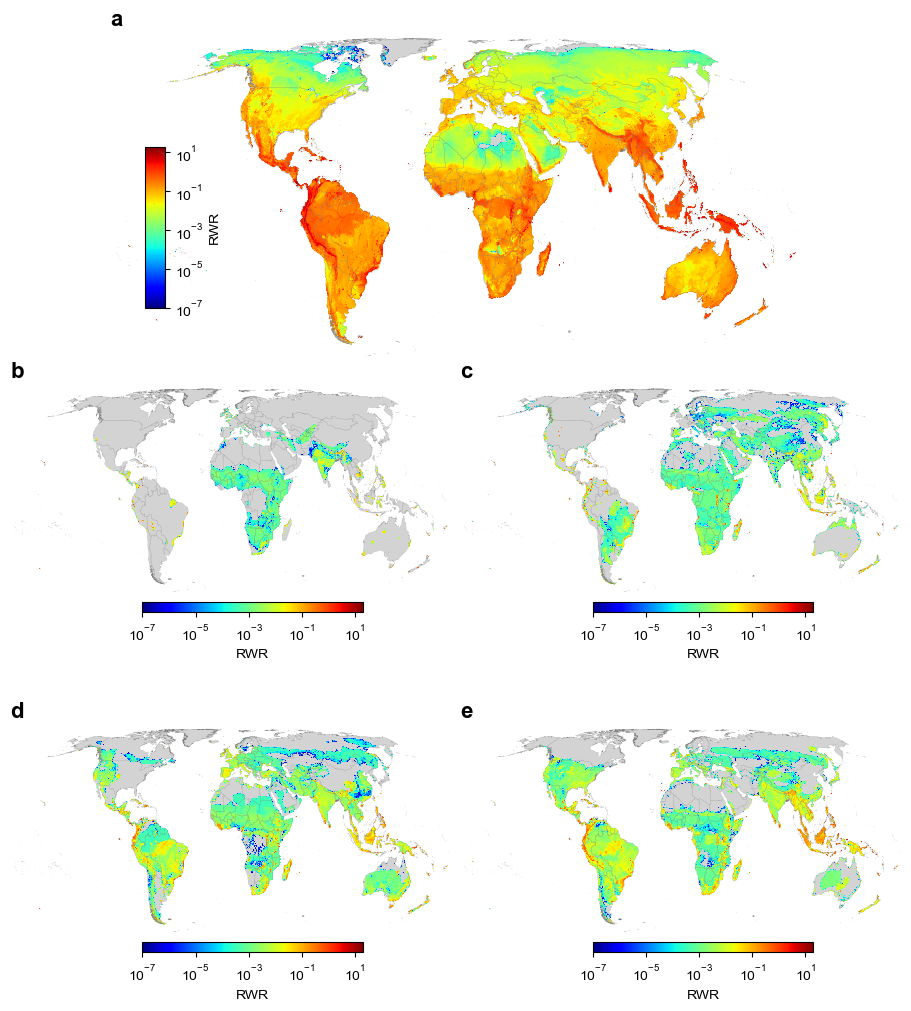

In [6]:
fig = draw_RWR_maps(taxon='birds')

fig.savefig(FIGURES / 'Supplementary-Figure-18.jpg', dpi=600, bbox_inches='tight')
# fig.savefig(FIGURES / 'Supplementary-Figure-18.pdf', dpi=600, bbox_inches='tight')